# BÀI 4 (TRANG 26): PHÂN LỚP DỮ LIỆU RED WINE QUALITY
- **Sinh viên thực hiện:** Dương Đại Phát
- **MSSV:** 6451071058
- **Nguồn dataset:** Google Drive (`winequality-red.csv`)

In [1]:
print("Dương Đại Phát - 6451071058")
import os
import subprocess
import sys

files_to_download = {
    "winequality-red.csv": "1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH",
}
for fname, fid in files_to_download.items():
    if not os.path.exists(fname):
        subprocess.check_call([sys.executable, "-m", "gdown", f"https://drive.google.com/uc?id={fid}", "-O", fname])

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import tree, metrics
from sklearn.naive_bayes import GaussianNB

data = pd.read_csv('winequality-red.csv')
data = data.dropna().reset_index(drop=True)
data.info()
data.head()

Dương Đại Phát - 6451071058


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng Pearson

Dương Đại Phát - 6451071058


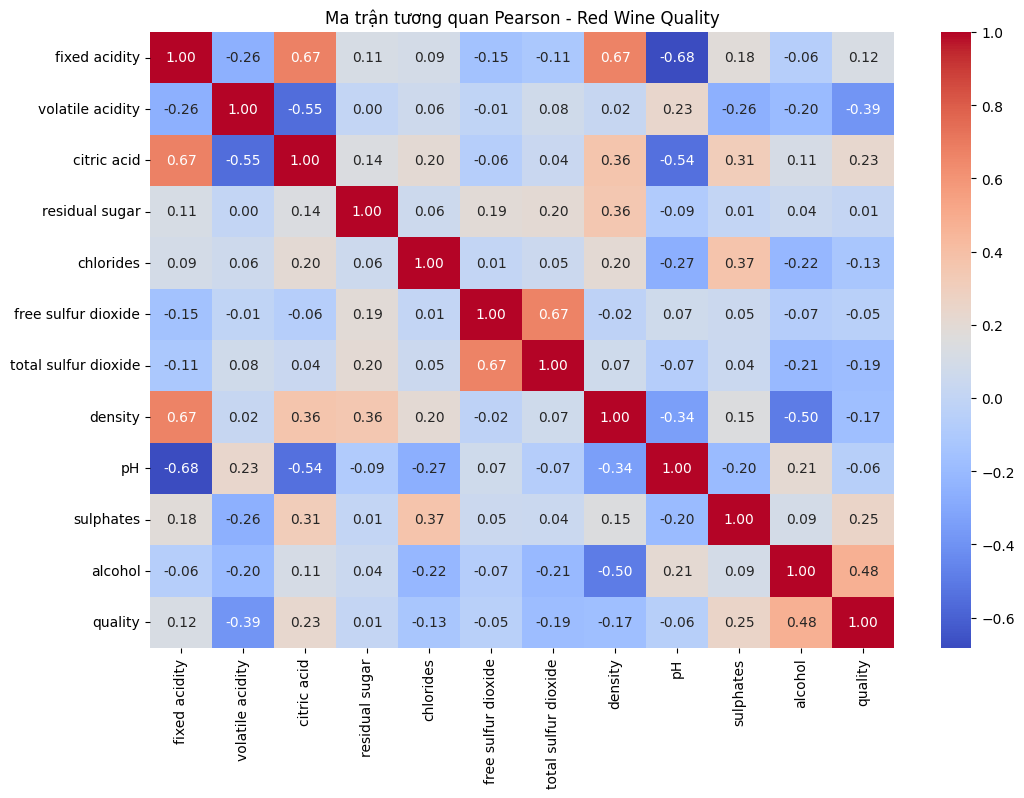

Nhận xét: Cặp tương quan cao nhất là fixed acidity & pH (-0.68), fixed acidity & citric acid (0.67),
fixed acidity & density (0.67), free & total sulfur dioxide (0.67). Không có cặp nào >= 0.8 nên giữ lại toàn bộ cột.


In [2]:
print("Dương Đại Phát - 6451071058")
plt.figure(figsize=(12, 8))
sns.heatmap(data.corr(method='pearson', numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Ma trận tương quan Pearson - Red Wine Quality")
plt.show()

print("Nhận xét: Cặp tương quan cao nhất là fixed acidity & pH (-0.68), fixed acidity & citric acid (0.67),")
print("fixed acidity & density (0.67), free & total sulfur dioxide (0.67). Không có cặp nào >= 0.8 nên giữ lại toàn bộ cột.")

## Câu 4: Tách thuộc tính (`features`) và thuộc tính quyết định (`labels = 'quality'`)

In [3]:
print("Dương Đại Phát - 6451071058")
features = data.drop('quality', axis=1)
labels = data['quality']
print("Features shape:", features.shape)
print("Phân bố nhãn quality:\n", labels.value_counts().sort_index())

Dương Đại Phát - 6451071058
Features shape: (1599, 11)
Phân bố nhãn quality:
 quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


## Câu 5: Kiểm tra và chuyển đổi các cột không phải dạng số về one-hot vector

In [4]:
print("Dương Đại Phát - 6451071058")
non_numeric_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Các cột không phải dạng số:", list(non_numeric_cols))
features_onehot = pd.get_dummies(features, columns=non_numeric_cols, dtype=int)
print("Tất cả thuộc tính đều đã ở dạng số. Kích thước features_onehot:", features_onehot.shape)
features_onehot.head()

Dương Đại Phát - 6451071058
Các cột không phải dạng số: []
Tất cả thuộc tính đều đã ở dạng số. Kích thước features_onehot: (1599, 11)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4


## Câu 6: Chia dữ liệu huấn luyện 70% và kiểm thử 30%

In [5]:
print("Dương Đại Phát - 6451071058")
X_train, X_test, y_train, y_test = train_test_split(features_onehot, labels, test_size=0.3, random_state=42)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

Dương Đại Phát - 6451071058
X_train: (1119, 11) | X_test: (480, 11)
y_train: (1119,) | y_test: (480,)


## Câu 7: Xây dựng cây quyết định ID3 (`criterion='entropy'`)

Dương Đại Phát - 6451071058
ID3 Accuracy: 0.5833333333333334
Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.08      0.12      0.10        17
           5       0.70      0.66      0.68       195
           6       0.60      0.60      0.60       200
           7       0.43      0.46      0.44        61
           8       0.25      0.17      0.20         6

    accuracy                           0.58       480
   macro avg       0.34      0.33      0.34       480
weighted avg       0.59      0.58      0.59       480



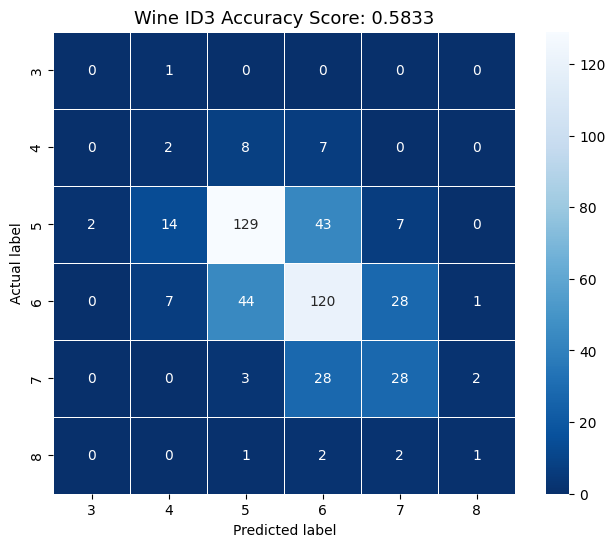

In [6]:
print("Dương Đại Phát - 6451071058")
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)
id3_pred = clf_id3.predict(X_test)

id3_score = metrics.accuracy_score(y_test, id3_pred)
print("ID3 Accuracy:", id3_score)
print("Report:\n", metrics.classification_report(y_test, id3_pred, zero_division=0))

id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf_id3.classes_, yticklabels=clf_id3.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Wine ID3 Accuracy Score: {id3_score:.4f}', size=13)
plt.show()

Dương Đại Phát - 6451071058


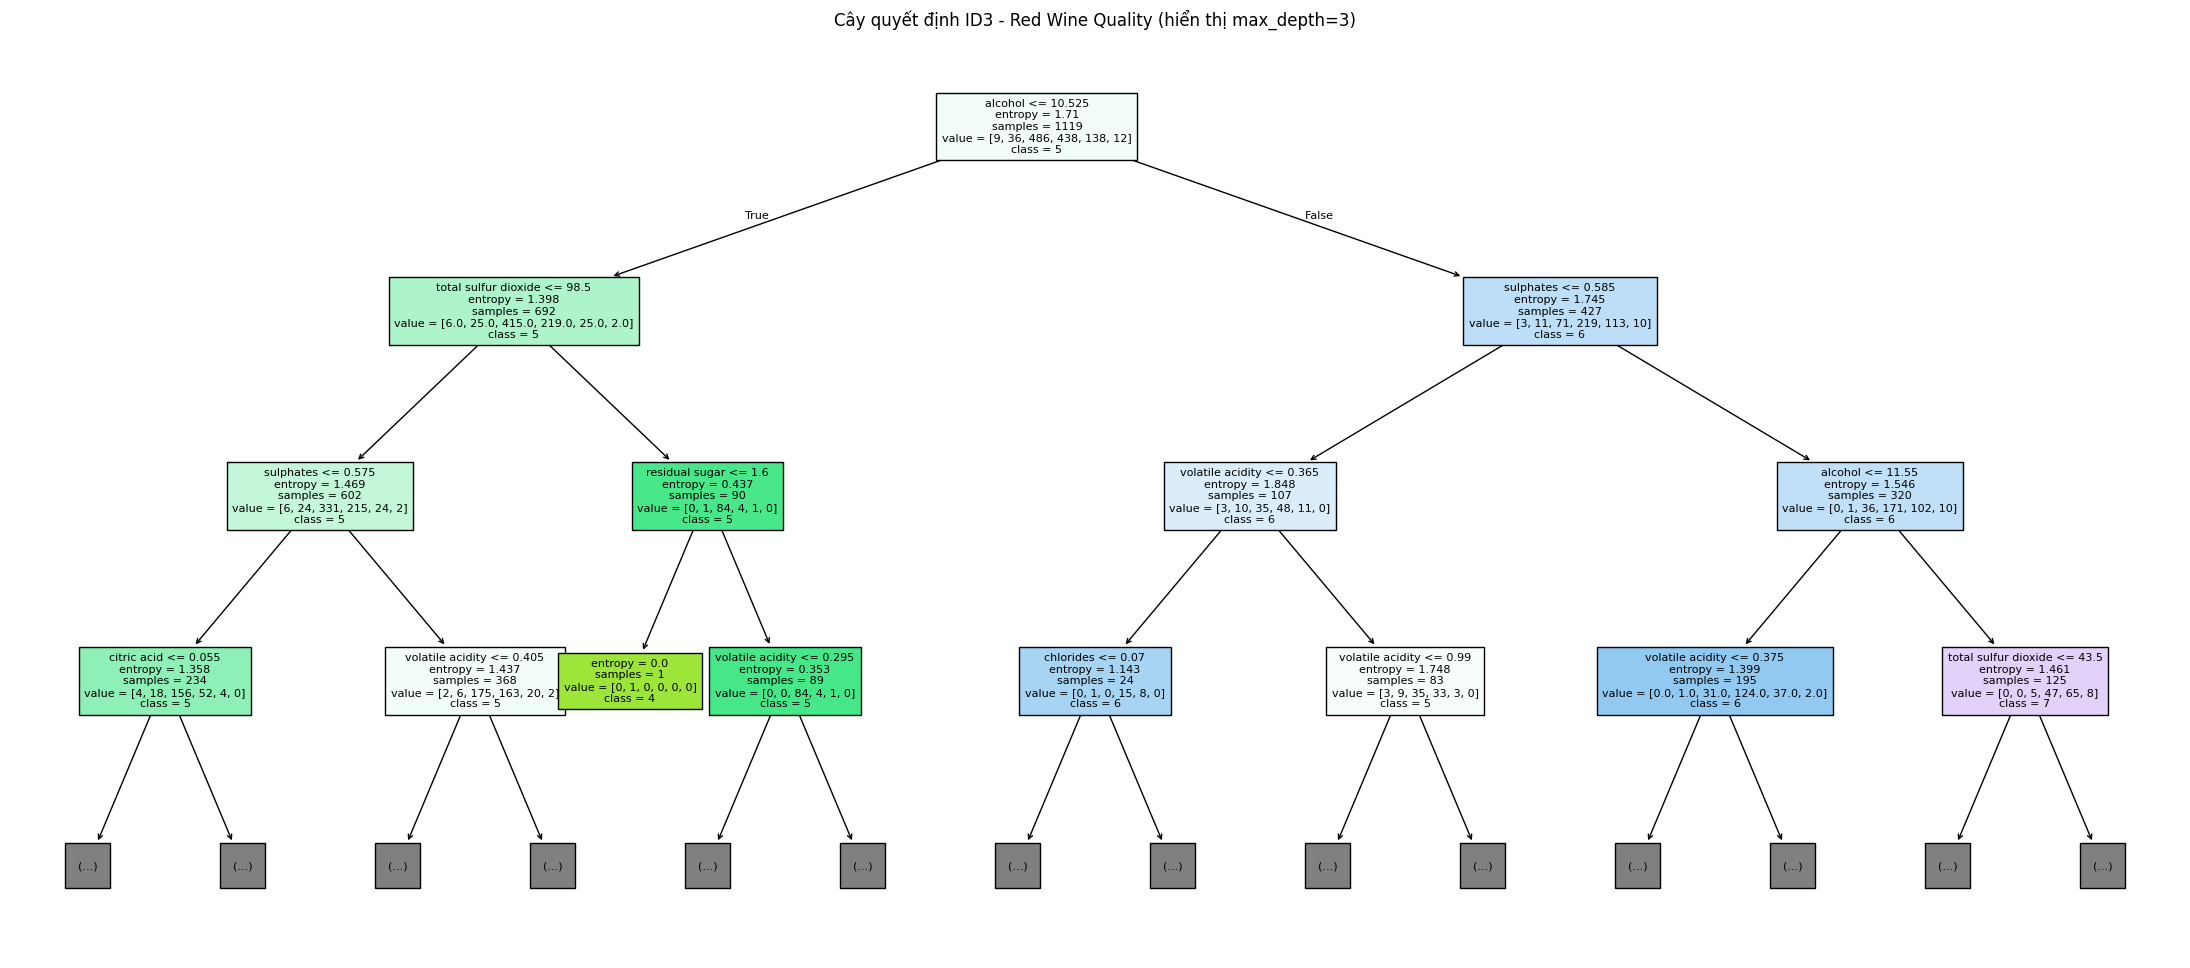

In [7]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(28, 12))
tree.plot_tree(clf_id3, filled=True, fontsize=8, max_depth=3,
               feature_names=features_onehot.columns, class_names=[str(c) for c in clf_id3.classes_])
plt.title("Cây quyết định ID3 - Red Wine Quality (hiển thị max_depth=3)")
plt.savefig('wine_tree_id3.png', dpi=100, bbox_inches='tight')
plt.show()

## Câu 8: Xây dựng cây quyết định CART (`criterion='gini'`)

Dương Đại Phát - 6451071058
CART Accuracy: 0.5625
Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.07      0.06      0.06        17
           5       0.64      0.62      0.63       195
           6       0.57      0.58      0.57       200
           7       0.45      0.49      0.47        61
           8       0.33      0.33      0.33         6

    accuracy                           0.56       480
   macro avg       0.34      0.35      0.35       480
weighted avg       0.56      0.56      0.56       480



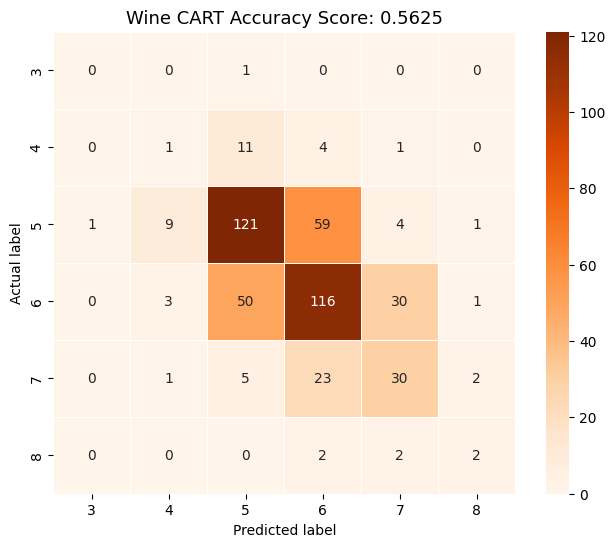

In [8]:
print("Dương Đại Phát - 6451071058")
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)

cart_score = metrics.accuracy_score(y_test, cart_pred)
print("CART Accuracy:", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred, zero_division=0))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Oranges',
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Wine CART Accuracy Score: {cart_score:.4f}', size=13)
plt.show()

Dương Đại Phát - 6451071058


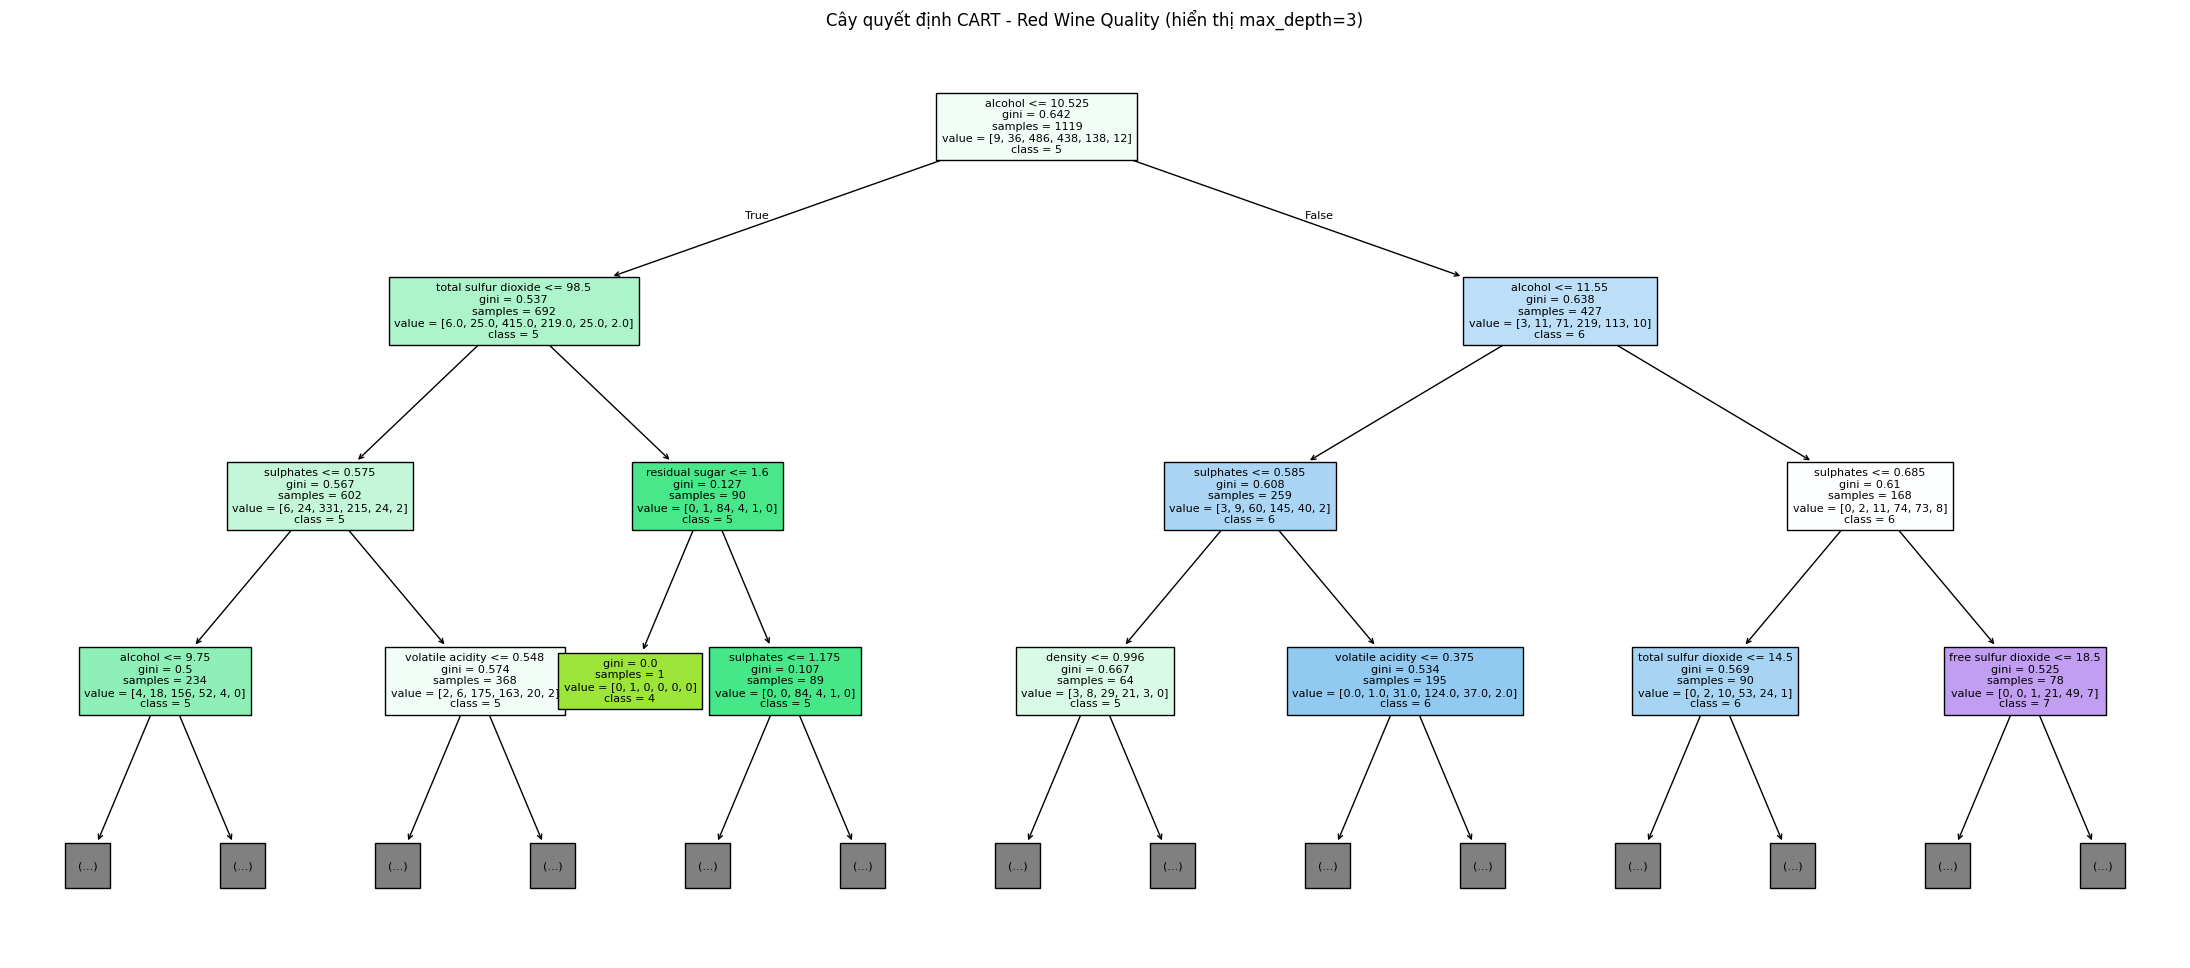

In [9]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(28, 12))
tree.plot_tree(clf_cart, filled=True, fontsize=8, max_depth=3,
               feature_names=features_onehot.columns, class_names=[str(c) for c in clf_cart.classes_])
plt.title("Cây quyết định CART - Red Wine Quality (hiển thị max_depth=3)")
plt.savefig('wine_tree_cart.png', dpi=100, bbox_inches='tight')
plt.show()

## Câu 9: Xây dựng mô hình Naïve Bayes (`GaussianNB`)

Dương Đại Phát - 6451071058
Naive Bayes Accuracy: 0.5416666666666666
Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.12      0.12      0.12        17
           5       0.68      0.62      0.65       195
           6       0.52      0.54      0.53       200
           7       0.40      0.49      0.44        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.29      0.29      0.29       480
weighted avg       0.55      0.54      0.54       480



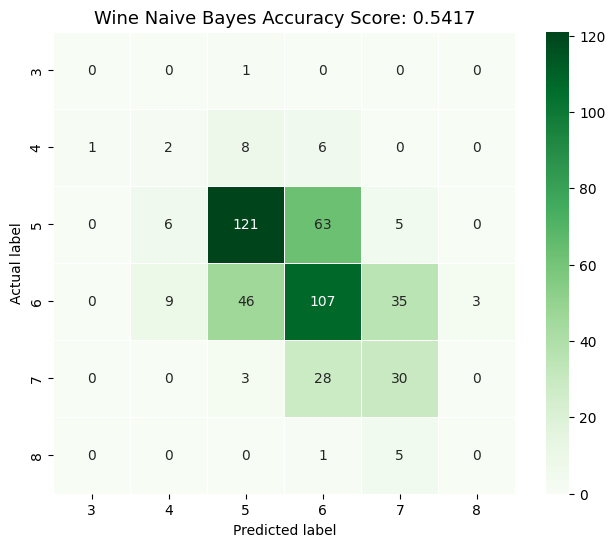

In [10]:
print("Dương Đại Phát - 6451071058")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Naive Bayes Accuracy:", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred, zero_division=0))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Wine Naive Bayes Accuracy Score: {bayes_score:.4f}', size=13)
plt.show()

## Câu 10: So sánh kết quả của các mô hình

In [11]:
print("Dương Đại Phát - 6451071058")
results = []
for name, pred in [("ID3 (Entropy)", id3_pred), ("CART (Gini)", cart_pred), ("Naive Bayes", bayes_pred)]:
    results.append({
        "Mô hình": name,
        "Accuracy": round(metrics.accuracy_score(y_test, pred), 4),
        "Precision (Weighted)": round(metrics.precision_score(y_test, pred, average='weighted', zero_division=0), 4),
        "Recall (Weighted)": round(metrics.recall_score(y_test, pred, average='weighted', zero_division=0), 4),
        "F1-score (Weighted)": round(metrics.f1_score(y_test, pred, average='weighted', zero_division=0), 4),
    })

df_compare = pd.DataFrame(results)
print(df_compare.to_string(index=False))
print("\nNhận xét: Cây quyết định (ID3 và CART) cho kết quả vượt trội hơn Naive Bayes trên tập Red Wine Quality (do các thuộc tính hóa lý liên tục có tương quan nhất định với nhau, vi phạm giả thiết độc lập có điều kiện của Naive Bayes).")

Dương Đại Phát - 6451071058
      Mô hình  Accuracy  Precision (Weighted)  Recall (Weighted)  F1-score (Weighted)
ID3 (Entropy)    0.5833                0.5941             0.5833               0.5883
  CART (Gini)    0.5625                0.5620             0.5625               0.5620
  Naive Bayes    0.5417                0.5471             0.5417               0.5433

Nhận xét: Cây quyết định (ID3 và CART) cho kết quả vượt trội hơn Naive Bayes trên tập Red Wine Quality (do các thuộc tính hóa lý liên tục có tương quan nhất định với nhau, vi phạm giả thiết độc lập có điều kiện của Naive Bayes).
